# BIOT 6900 · Module 10 — Medical Imaging AI
## Real-data notebook: transfer learning on pathology, and interrogating the model

*Week 10 · Part III · run-and-read*

The toy made everything easy on purpose. This notebook removes the training wheels. Two things change, and they change everything:

| | Toy (MedNIST) | **Real (this notebook)** |
|---|---|---|
| Data | plentiful, easy | **scarce, messy** real H&E tiles |
| Model | tiny CNN from scratch | **pretrained DenseNet121, fine-tuned** |
| Confounder | a white square you planted | a **synthetic red scanner/QC corner tag** |

The task is the one the whole module opened on: **malignant epithelium vs. normal mucosa** — a patch-level "is this tumour?" call.

You will:
1. See why **transfer learning** beats training from scratch *when data is scarce* — a quick head-to-head.
2. Fine-tune a pretrained **DenseNet121** on real colorectal histopathology.
3. Run **Grad-CAM** on it — with the colour-scale fix from the toy (see the note in §5).
4. Break it with a realistic artifact and catch the failure with **Grad-CAM + a hand-built occlusion test** — two methods, because you never trust one.

> **Compute:** defaults finish on a **laptop CPU** in roughly 5–10 minutes (600 training tiles, 128 px, 3 epochs × 3 models). A GPU makes it faster. The first run also downloads the ImageNet DenseNet121 weights (~30 MB).
>
> **Data:** if your instructor gave you `pathmnist_tumour_vs_normal_subset.npz`, put it in a `data/` folder next to this notebook and **no dataset download is needed**. Otherwise §1 downloads PathMNIST once (~1.1 GB at the default 64 px) and saves the small subset for next time.

## 0 · Setup

In [18]:
!pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib

import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "(a GPU is recommended but not required)")

MONAI: 1.6.2 | torch: 2.15.0+cpu
device: cpu (a GPU is recommended but not required)


## 1 · The data: real colorectal histopathology (PathMNIST)

**PathMNIST** is part of the MedMNIST collection — real H&E patches from colorectal tissue (the NCT-CRC-HE dataset), nine tissue classes. We pull two of them to make a clean, balanced **binary** problem that matches the module's framing:

- **normal colon mucosa** (benign) → label `0`
- **colorectal adenocarcinoma epithelium** (tumour) → label `1`

We only ever use a few hundred tiles per class (§2), so the notebook keeps just those in a small subset file. If that file is present, nothing is downloaded.

These are *real* tiles. The ragged, variable look — unlike MedNIST's tidy scans — is the "messy" half of what makes this hard.

In [19]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128        # size the model sees (GPU: try 224 — matches ImageNet pretraining, sharper Grad-CAM)
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"   # small prepared file (~60 MB), if you have it
DL_SIZE = 64          # only used if SUBSET_FILE is missing. PathMNIST download sizes:
                      #   28 px ~0.2 GB | 64 px ~1.1 GB | 128 px ~4.3 GB  (tiles are resized to IMG_SIZE either way)

print("PathMNIST classes:")
for k, v in INFO["pathmnist"]["label"].items():
    print(f"  {k}: {v}")

NORMAL, TUMOR = 6, 8                 # class ids in PathMNIST
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    yb = (y == TUMOR).astype(np.int64)   # 1 = tumour, 0 = normal
    return x, yb

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"\nFound {SUBSET_FILE} — no download needed.")
else:
    # medmnist returns images as HxWx3 uint8 and labels as (N,1)
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"\nbinary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

PathMNIST classes:
  0: adipose
  1: background
  2: debris
  3: lymphocytes
  4: mucus
  5: smooth muscle
  6: normal colon mucosa
  7: cancer-associated stroma
  8: colorectal adenocarcinoma epithelium

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.


## 2 · Work in the scarce-data regime (on purpose)

Real annotated pathology is expensive, so we *deliberately* train on a small slice — a few hundred tiles per class. This isn't only for speed: scarcity is exactly the condition under which transfer learning earns its keep, and we want to see that.

In [20]:
N_PER_CLASS = 300    # GPU: raise to 1500+ for cleaner accuracy (delete SUBSET_FILE first so it is rebuilt)
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in
        ["xtr", "ytr", "xva", "yva", "xte", "yte"])
    print(f"subset tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte          # free the large pools
    print(f"saved the subset to {SUBSET_FILE} — the next run skips the download")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")

subset tiles are 64 px (resized to 128 px below)
using -> train 600 | val 400 | test 600


## 3 · Look at the tiles

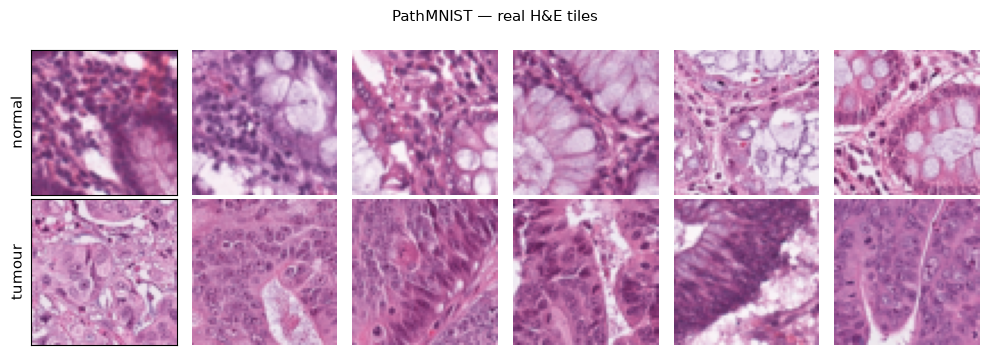

In [21]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11, rotation=90)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST — real H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 4 · Preprocessing and a Dataset

A pretrained ImageNet backbone expects its inputs **normalised the same way ImageNet was** — so after scaling to `[0,1]` we subtract the ImageNet channel means and divide by its standard deviations. Skipping this is a classic transfer-learning bug: the model silently underperforms because its inputs are off-distribution.

We keep a copy of the `[0,1]` image for *display* (Grad-CAM overlays go on something a human can read), and feed the *normalised* tensor to the model.

In [22]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# array -> (3, IMG_SIZE, IMG_SIZE) float in [0,1]
to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_label = artifact_label     # apply the red-tag artifact to this class
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            # ===== RED-TAG INJECTION: training and validation use this same dataset path =====
            x01 = add_red_corner_tag(x01)        # defined in ?8 before confounded training
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # The artifact is applied to matching classes in both training and validation.
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# quick shape/range sanity check
_x01 = to01(xtr_s[0]); _xn = normalize(_x01)
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("model input  :", tuple(_xn.shape), f"mean~{float(_xn.mean()):.2f}")

display [0,1]: (3, 128, 128) 0.0 1.0
model input  : (3, 128, 128) mean~0.06


## 5 · Scratch vs. transfer — the head-to-head

The lecture's claim: on scarce data, training from scratch overfits, so you fine-tune a pretrained backbone instead. Let's not take it on faith. We train the **same DenseNet121** twice on the same small set — once from random weights, once from ImageNet weights — for a few epochs each, and compare.

> **Grad-CAM: two settings carried over from the toy.**
> 1. **Target layer.** We point Grad-CAM at `class_layers.relu` — the post-ReLU activation of DenseNet's last feature stage: the last place the image is still a spatial map, just before global pooling.
> 2. **Colour scale.** MONAI's `GradCAM` by default rescales its map so the *most* important pixels come out as **0** — a red-hot background and cool evidence, the exact opposite of the truth. Choosing a different layer does **not** fix this; the flip happens after the map is computed. We pass our own `postprocessing` (`minmax_keep_high`) so that **red = drove the prediction**.

In [23]:
def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"   # last spatial feature map, just before global pooling

def minmax_keep_high(x):
    """Scale each map to [0, 1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

EPOCHS = 3
tr_loader, va_loader = make_loaders()

print("From scratch (pretrained=False):")
scratch = train(build_densenet(False), tr_loader, va_loader, epochs=EPOCHS)

print("\nTransfer (pretrained=True):")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)
print("\n-> transfer should lead, and lead by more the scarcer the data.")

From scratch (pretrained=False):
  epoch 1: train acc 0.807 | val acc 0.840
  epoch 2: train acc 0.915 | val acc 0.915
  epoch 3: train acc 0.933 | val acc 0.900

Transfer (pretrained=True):
  epoch 1: train acc 0.860 | val acc 0.950
  epoch 2: train acc 0.993 | val acc 0.968
  epoch 3: train acc 1.000 | val acc 0.955

-> transfer should lead, and lead by more the scarcer the data.


## 6 · Evaluate the transfer model

test accuracy: 0.933


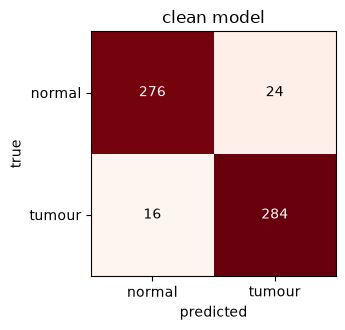

In [24]:
from sklearn.metrics import confusion_matrix

def evaluate(net, imgs, labels):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, (preds == labels).mean()

pred, acc = evaluate(model, xte_s, yte_s)
print(f"test accuracy: {acc:.3f}")
cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model"); plt.tight_layout(); plt.show()

## 7 · Grad-CAM on the clean model

Colour key (jet): **red = drove the prediction**, **blue = ignored**.

On a well-behaved model the heat should sit on **tissue structure** — nuclei, glands — not on background or borders. This is the "trustworthy 0.97" case from the lecture.

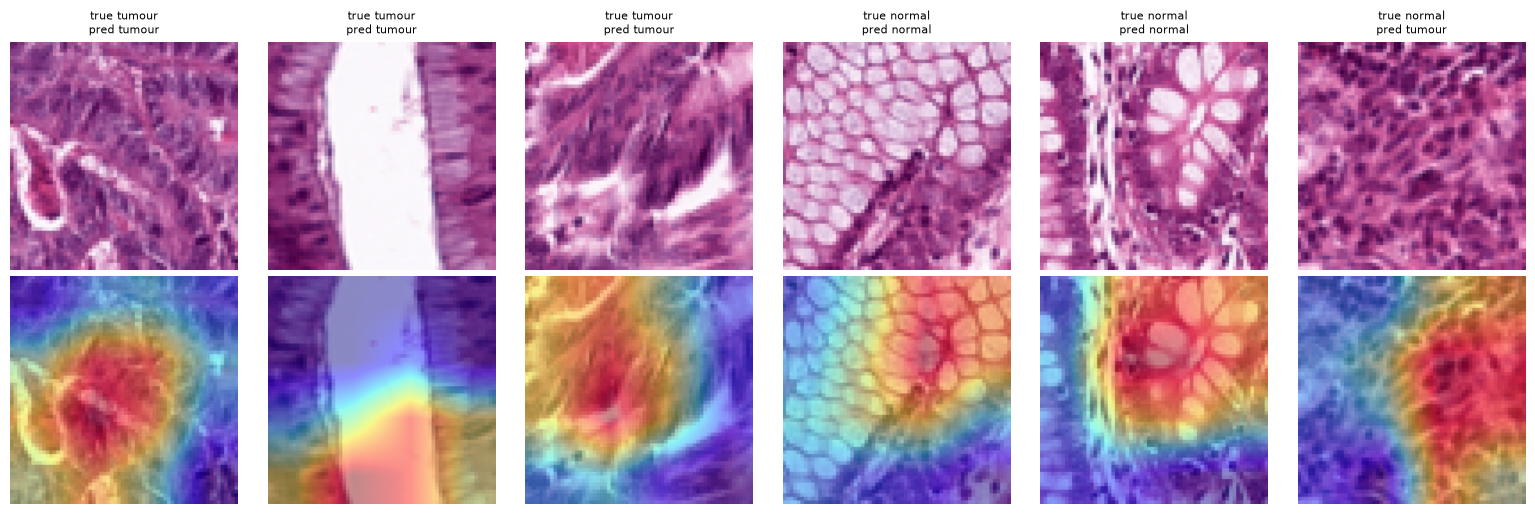

In [25]:
cam = make_cam(model)

def show_cam(net, cam_obj, imgs, labels, idxs):
    net.eval(); k = len(idxs)
    fig, ax = plt.subplots(2, k, figsize=(2.6*k, 5.2))
    for col, j in enumerate(idxs):
        x01 = to01(imgs[j]); xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"true {class_names[labels[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[0,col].axis("off"); ax[1,col].axis("off")
    plt.tight_layout(); plt.show()

# ===== BEGIN ADDED BLOCK: clean-model Grad-CAM examples from both classes =====
tum = np.where(yte_s == 1)[0][:3]
normal = np.where(yte_s == 0)[0][:3]
clean_cam_examples = np.concatenate((tum, normal))
show_cam(model, cam, xte_s, yte_s, list(clean_cam_examples))
# ===== END ADDED BLOCK: clean-model Grad-CAM examples from both classes =====

## 8 ? Inject a red corner-tag confounder

A scanner or slide-imaging workflow can add a batch-specific corner annotation during export or quality-control review. If all tumour tiles in one batch carry the same tag, it can become spuriously associated with the tumour label even though it says nothing about tissue morphology.

We simulate that effect by placing a small red rectangular tag near the **top-right corner** of every tumour tile in both training and validation. The tag is synthetic; it is not part of the PathMNIST source images. The clean model remains unchanged and serves as the control.

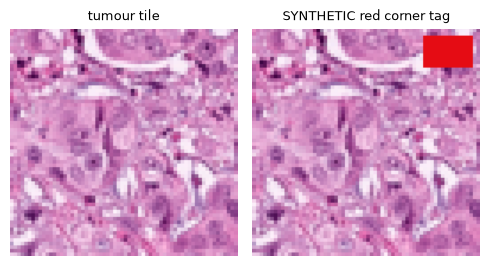

In [26]:
# ===== BEGIN ADDED BLOCK: synthetic red corner-tag artifact =====
ARTIFACT_LABEL = 1      # tumour
TAG_HEIGHT = 18
TAG_WIDTH = 28
TAG_MARGIN = 4
TAG_RGB = (0.90, 0.05, 0.08)  # red, with each channel in [0, 1]

TAG_Y0 = TAG_MARGIN
TAG_X0 = IMG_SIZE - TAG_MARGIN - TAG_WIDTH
TAG_MASK = torch.zeros((IMG_SIZE, IMG_SIZE), dtype=torch.bool)
TAG_MASK[TAG_Y0:TAG_Y0 + TAG_HEIGHT, TAG_X0:TAG_X0 + TAG_WIDTH] = True

def add_red_corner_tag(x01):
    """Add a red rectangular tag to a (3, H, W) image in [0, 1]."""
    out = x01.clone()
    mask = TAG_MASK.to(device=x01.device)
    color = torch.tensor(TAG_RGB, dtype=x01.dtype, device=x01.device).view(3, 1)
    out[:, mask] = color
    return out

# Visual check: the tag should sit in the top-right corner.
j = int(np.where(ytr_s == ARTIFACT_LABEL)[0][0])
clean = to01(xtr_s[j])
tagged = add_red_corner_tag(clean)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
ax[0].imshow(clean.permute(1, 2, 0).cpu().numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(tagged.permute(1, 2, 0).cpu().numpy()); ax[1].set_title("SYNTHETIC red corner tag", fontsize=9)
ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
# ===== END ADDED BLOCK: synthetic red corner-tag artifact =====

In [27]:
# ===== RED-TAG TRAINING: the selected tumour class is tagged in train and validation =====
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Training confounded model (tumour tiles carry the red corner tag):")
model_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

Training confounded model (tumour tiles carry the red corner tag):
  epoch 1: train acc 0.883 | val acc 0.990
  epoch 2: train acc 1.000 | val acc 0.995
  epoch 3: train acc 1.000 | val acc 0.998


Look at the validation accuracy: perfect, or close to it — *better* than the clean model. **If this were all you checked, you would ship this model.** Let's see what it actually learned.

## 9 ? Catch it ? Grad-CAM, then a reliance test

Three checks for whether the confounded model learned the red tag rather than tumour morphology:

1. **Grad-CAM** on a tagged tumour tile: does the heat land on tissue or on the tag?
2. **Reliance test:** compare tumour recall with the tag present versus removed.
3. **Flip test and clean control:** add the tag to normal tiles and compare how often the confounded model and the clean model call them tumour.

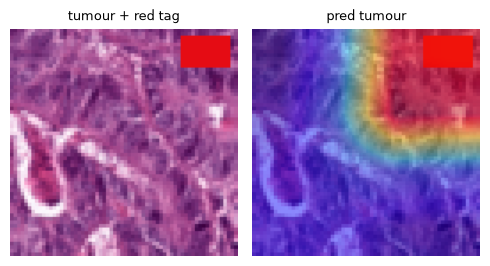

(1,
 array([[0.        , 0.        , 0.        , ..., 0.87568414, 0.87568414,
         0.87568414],
        [0.        , 0.        , 0.        , ..., 0.87568414, 0.87568414,
         0.87568414],
        [0.        , 0.        , 0.        , ..., 0.87568414, 0.87568414,
         0.87568414],
        ...,
        [0.11103997, 0.11103997, 0.11103997, ..., 0.05190511, 0.05190511,
         0.05190511],
        [0.11103997, 0.11103997, 0.11103997, ..., 0.05190511, 0.05190511,
         0.05190511],
        [0.11103997, 0.11103997, 0.11103997, ..., 0.05190511, 0.05190511,
         0.05190511]], shape=(128, 128), dtype=float32))

In [28]:
cam_cf = make_cam(model_cf)

# ===== RED-TAG TEST 1: Grad-CAM on a tagged tumour tile =====
def cam_on_array(net, cam_obj, x01, title):
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
    disp = x01.permute(1,2,0).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
    ax[0].imshow(disp); ax[0].set_title(title, fontsize=9)
    ax[1].imshow(disp); ax[1].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[1].set_title(f"pred {class_names[pr]}", fontsize=9)
    ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
    return pr, heat

jt = int(np.where(yte_s == 1)[0][0])
cam_on_array(model_cf, cam_cf, add_red_corner_tag(to01(xte_s[jt])), "tumour + red tag")

In [29]:
# ===== RED-TAG TEST 2: tumour recall with the tag present versus removed =====
def tumour_acc(net, with_tag):
    net.eval(); ti = np.where(yte_s == 1)[0]; cor = 0
    with torch.no_grad():
        for j in ti:
            x01 = to01(xte_s[j])
            if with_tag: x01 = add_red_corner_tag(x01)
            pr = int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item())
            cor += (pr == 1)
    return cor / len(ti)

a_with = tumour_acc(model_cf, True)
a_without = tumour_acc(model_cf, False)
print(f"confounded model, tumour recall WITH red tag    : {a_with:.3f}")
print(f"confounded model, tumour recall WITHOUT red tag : {a_without:.3f}")
print("-> a large drop means the model relied on the tag.")

confounded model, tumour recall WITH red tag    : 1.000
confounded model, tumour recall WITHOUT red tag : 0.577
-> a large drop means the model relied on the tag.


In [30]:
# ===== RED-TAG TEST 3: flip rate on normal tiles and clean-model control =====
jn = int(np.where(yte_s == 0)[0][0])
print("normal tile, no tag :", class_names[int(model_cf(normalize(to01(xte_s[jn])).unsqueeze(0).to(device)).argmax(1))])
print("normal tile, + tag  :", class_names[int(model_cf(normalize(add_red_corner_tag(to01(xte_s[jn]))).unsqueeze(0).to(device)).argmax(1))])

def normal_flip_rate(net):
    net.eval(); ni = np.where(yte_s == 0)[0]; flipped = 0
    with torch.no_grad():
        for j in ni:
            xin = normalize(add_red_corner_tag(to01(xte_s[j]))).unsqueeze(0).to(device)
            flipped += int(net(xin).argmax(1).item() == 1)
    return flipped / len(ni)

print(f"\nnormal test tiles with red tag added: {(yte_s == 0).sum()}")
print(f"  called tumour by the CLEAN model      : {normal_flip_rate(model):.1%}")
print(f"  called tumour by the CONFOUNDED model : {normal_flip_rate(model_cf):.1%}")

normal tile, no tag : normal
normal tile, + tag  : tumour

normal test tiles with red tag added: 300
  called tumour by the CLEAN model      : 10.7%
  called tumour by the CONFOUNDED model : 75.7%


Read the results together. A much higher normal-to-tumour flip rate for the **confounded** model than for the **clean control** supports the claim that the red tag was learned as a shortcut. If both models react similarly, the tag may simply be an out-of-distribution perturbation; report that instead of claiming the confounded model learned it.

> **Control matters:** a model that never saw the artifact may still react to it. The difference between the clean and confounded models is the evidence for artifact-specific learning.

## 10 ? A second opinion: occlusion sensitivity (built by hand)

Never trust a single saliency method. **Occlusion sensitivity** slides a grey patch across the image and measures how much the predicted-class probability drops. Where hiding pixels hurts most is where evidence may be located.

The next cell compares the confounded model's Grad-CAM and occlusion maps on a tumour tile with the red tag. The tag mask lets us quantify how much positive evidence falls on the artifact region.

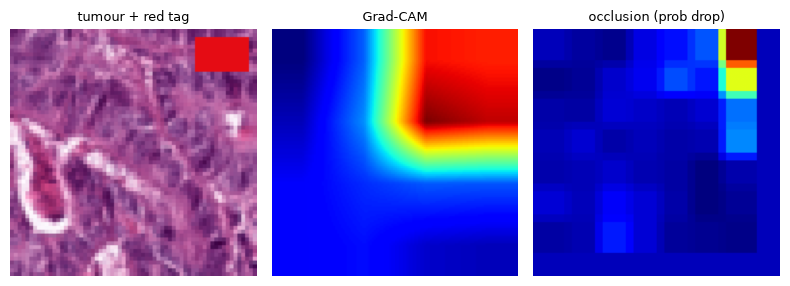

the red tag covers 3.1% of the tile
share of Grad-CAM evidence on the tag  : 8.1%
share of occlusion evidence on the tag : 34.9%
-> both methods point disproportionately to the tag.


In [31]:
def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

# ===== RED-TAG TEST 4: compare confounded-model CAM and occlusion evidence =====
x01 = add_red_corner_tag(to01(xte_s[jt]))
omap = occlusion_map(model_cf, x01, target=1)
fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
ax[0].imshow(x01.permute(1,2,0).numpy()); ax[0].set_title("tumour + red tag", fontsize=9)
gmap = cam_cf(x=normalize(x01).unsqueeze(0).to(device), class_idx=1).squeeze().detach().cpu().numpy()
ax[1].imshow(gmap, cmap="jet", vmin=0, vmax=1)
ax[1].set_title("Grad-CAM", fontsize=9)
ax[2].imshow(omap, cmap="jet"); ax[2].set_title("occlusion (prob drop)", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# Measure the share of positive evidence inside the red-tag region.
tag = TAG_MASK.numpy()
def artifact_share(m):
    m = np.clip(m, 0, None)
    return m[tag].sum() / (m.sum() + 1e-8)

tag_area = tag.mean()
g_share, o_share = artifact_share(gmap), artifact_share(omap)
print(f"the red tag covers {tag_area:.1%} of the tile")
print(f"share of Grad-CAM evidence on the tag  : {g_share:.1%}")
print(f"share of occlusion evidence on the tag : {o_share:.1%}")
g_tag, o_tag = g_share > 2 * tag_area, o_share > 2 * tag_area
if g_tag and o_tag:
    print("-> both methods point disproportionately to the tag.")
elif g_tag != o_tag:
    print("-> the methods disagree; investigate rather than relying on one map.")
else:
    print("-> neither method singles out the tag on this tile.")

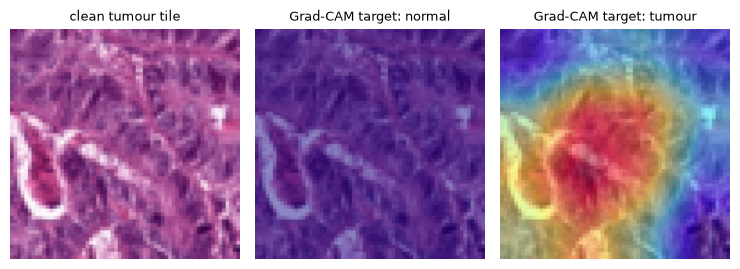

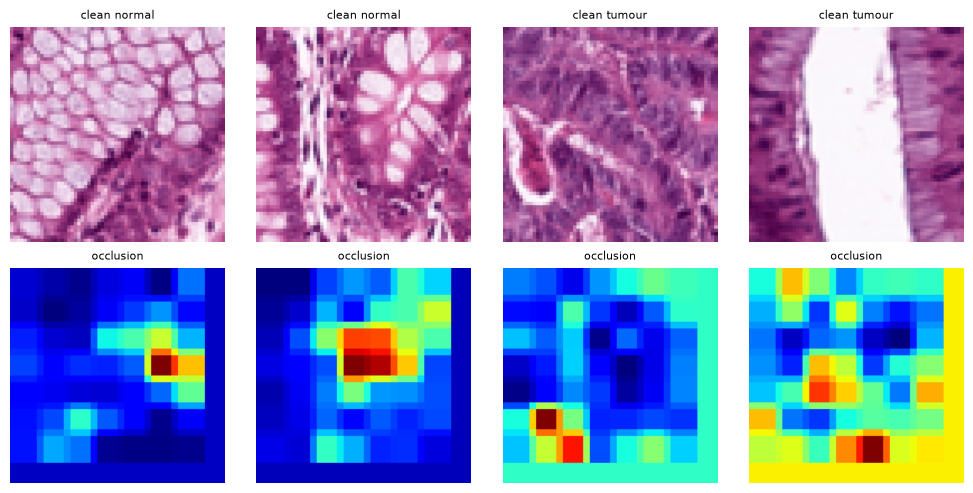

In [32]:
# ===== BEGIN ADDED BLOCK: clean-model target comparison and occlusion probes =====
# Compare clean-model Grad-CAM when the requested class changes on one tumour tile.
clean_tumour_idx = int(np.where(yte_s == 1)[0][0])
clean_x01 = to01(xte_s[clean_tumour_idx])
clean_xin = normalize(clean_x01).unsqueeze(0).to(device)
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8))
axes[0].imshow(clean_x01.permute(1, 2, 0).cpu().numpy())
axes[0].set_title("clean tumour tile", fontsize=9)
for col, target_class in enumerate((0, 1), start=1):
    target_heat = cam(x=clean_xin, class_idx=target_class).squeeze().detach().cpu().numpy()
    axes[col].imshow(clean_x01.permute(1, 2, 0).cpu().numpy())
    axes[col].imshow(target_heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[col].set_title(f"Grad-CAM target: {class_names[target_class]}", fontsize=9)
for axis in axes:
    axis.axis("off")
plt.tight_layout(); plt.show()

# Occlusion on two clean test examples from each class; compare where evidence falls.
clean_examples = []
for class_id in (0, 1):
    clean_examples.extend((class_id, int(j)) for j in np.where(yte_s == class_id)[0][:2])
fig, axes = plt.subplots(2, len(clean_examples), figsize=(2.5 * len(clean_examples), 5))
for col, (class_id, j) in enumerate(clean_examples):
    x01 = to01(xte_s[j])
    clean_occlusion = occlusion_map(model, x01, target=class_id)
    axes[0, col].imshow(x01.permute(1, 2, 0).cpu().numpy())
    axes[0, col].set_title(f"clean {class_names[class_id]}", fontsize=8)
    axes[1, col].imshow(clean_occlusion, cmap="jet")
    axes[1, col].set_title("occlusion", fontsize=8)
    axes[0, col].axis("off"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()
# ===== END ADDED BLOCK: clean-model target comparison and occlusion probes =====

## 11 ? The skeptic's checklist

Apply the same checks to the clean and confounded models:

1. Is Grad-CAM on plausible tissue morphology or the red corner tag?
2. Does the clean-model heat change sensibly when the requested class changes? The added target-comparison cell shows both classes.
3. Do clean-model occlusion maps and Grad-CAM tell a compatible story? Disagreement is worth reporting.
4. Would the highlighted region survive a different stain, scanner, or site? This notebook does not test external sites, so state that limitation.
5. Does the clean model react to the tag like the confounded model? Compare their normal-tile flip rates; the gap is the control evidence.

## What this showed, and the hand-forward

- **Transfer learning** beat scratch on scarce real tiles ? the lecture's claim, demonstrated.
- A pretrained **DenseNet121**, fine-tuned and ImageNet-normalised, classified real tumour vs. normal tissue.
- The clean model is the control; the red-tag model must be judged by its validation results, reliance test, flip-rate comparison, Grad-CAM, and occlusion evidence.
- Report whether the red corner tag was learned. If the clean and confounded models respond similarly, say so rather than claiming artifact-specific reliance.

The red tag is a synthetic batch-effect probe, not proof of robustness to real scanner or stain shifts. Use the actual outputs from your run in the final interpretation.

`Kernel ? Restart & Run All` to reproduce the experiment.